# 03 — Interprétation : SHAP, dependence plots et analyse par segments

Challenge NPS — Phase 3. Interprète le modèle final
(`mord.LogisticAT`, `docs/decisions.md` D21) persisté dans
`models/final_model.joblib`, entraîné sur `respondent_train` (split
réaliste). Couvre : SHAP global, SHAP par classe, dependence plots des
4 principaux drivers de détraction, et une analyse par segments
(ancienneté, type de contrat, type d'accès internet).

**Note méthodologique importante.** `mord.LogisticAT` est un modèle
linéaire ordinal, pas un arbre — `shap.TreeExplainer` (rapide, exact)
ne s'applique donc pas. On utilise `shap.Explainer` de façon
model-agnostic sur `pipeline.predict_proba`, ce qui nécessite un espace
d'entrée purement numérique : les valeurs SHAP sont donc calculées sur
l'espace **transformé** (après `StandardScaler` + `OneHotEncoder`), pas
sur les colonnes métier brutes. Chaque catégorie devient une colonne
factice (`categorical__Contract_Month-to-month`, etc.) — un peu moins
lisible qu'un nom de colonne métier direct, mais c'est l'approche
standard et robuste pour des données mixtes numériques/catégorielles
avec un modèle non-arbre, et les noms de colonnes restent
suffisamment explicites pour l'interprétation métier.


In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

sys.path.append(str(Path("..") / "src"))
import config
from features import build_feature_matrix

warnings.filterwarnings("ignore")
np.random.seed(config.SEED)
plt.rcParams["figure.dpi"] = 110

artifact = joblib.load(config.MODELS_DIR / "final_model.joblib")
pipeline = artifact["pipeline"]
feature_columns = artifact["feature_columns"]
prep = pipeline.named_steps["prep"]
model = pipeline.named_steps["model"]

print(artifact["model_description"])
print(f"Trained on: {artifact['trained_on']} ({artifact['n_train_rows']} rows)")


mord.LogisticAT (alpha=1.0, class-balanced sample weights), uncalibrated (docs/decisions.md D21; calibration rejected per D19).
Trained on: respondent_train (realistic split, docs/decisions.md D8) (1056 rows)


In [2]:
labeled = pd.read_parquet(config.LABELED_DATASET_PATH)
realistic_split = pd.read_parquet(config.REALISTIC_SPLIT_PATH)
X = build_feature_matrix(labeled, include_geo=False)
y = labeled[[config.ID_COL, config.TARGET_COL]]
data = X.merge(y, on=config.ID_COL).merge(realistic_split, on=config.ID_COL)

train = data[data["split"] == "respondent_train"]
test = data[data["split"] == "silent_test"]

feature_names_t = prep.get_feature_names_out()
X_train_t = pd.DataFrame(prep.transform(train[feature_columns]), columns=feature_names_t, index=train.index)
X_test_t = pd.DataFrame(prep.transform(test[feature_columns]), columns=feature_names_t, index=test.index)

print(f"Train (respondent_train): {X_train_t.shape}, Test (silent_test): {X_test_t.shape}")


Train (respondent_train): (1056, 74), Test (silent_test): (5987, 74)


## 1. Calcul des valeurs SHAP

SHAP est calculé sur un échantillon de 1200 clients du test silencieux
(pas les 5987, pour un temps de calcul raisonnable — largement
suffisant pour des agrégats stables par segment) et un fond de
référence (`background`) de 50 clients du train, conformément à la
pratique standard de `shap.Explainer` pour un modèle boîte noire.


In [3]:
DETRACTOR_IDX = config.NPS_CATEGORIES.index("Detractor")
N_BACKGROUND = 50
N_SAMPLE = 1200

background = shap.sample(X_train_t, N_BACKGROUND, random_state=config.SEED)
sample_idx = test.sample(N_SAMPLE, random_state=config.SEED).index
X_sample_t = X_test_t.loc[sample_idx]
test_sample = test.loc[sample_idx]

explainer = shap.Explainer(model.predict_proba, background)
shap_values = explainer(X_sample_t)
print(f"SHAP values shape: {shap_values.values.shape}  (samples, features, classes)")
print(f"Class order: {config.NPS_CATEGORIES}")



PermutationExplainer explainer:   0%|          | 1/1200 [00:00<?, ?it/s]


PermutationExplainer explainer:   1%|          | 7/1200 [00:10<00:22, 53.64it/s]


PermutationExplainer explainer:   1%|          | 13/1200 [00:10<00:23, 51.20it/s]


PermutationExplainer explainer:   2%|▏         | 19/1200 [00:10<00:24, 47.56it/s]


PermutationExplainer explainer:   2%|▏         | 24/1200 [00:10<00:24, 47.68it/s]

...


PermutationExplainer explainer:  99%|█████████▉| 1187/1200 [00:37<00:00, 45.73it/s]


PermutationExplainer explainer:  99%|█████████▉| 1192/1200 [00:37<00:00, 41.57it/s]


PermutationExplainer explainer: 100%|█████████▉| 1197/1200 [00:37<00:00, 37.57it/s]


PermutationExplainer explainer: 1201it [00:37, 31.60it/s]                          

SHAP values shape: (1200, 74, 3)  (samples, features, classes)
Class order: ['Detractor', 'Passive', 'Promoter']


## 2. SHAP global

Importance moyenne (|SHAP| moyen, toutes classes confondues) des 15
features les plus influentes sur la prédiction NPS dans son ensemble.


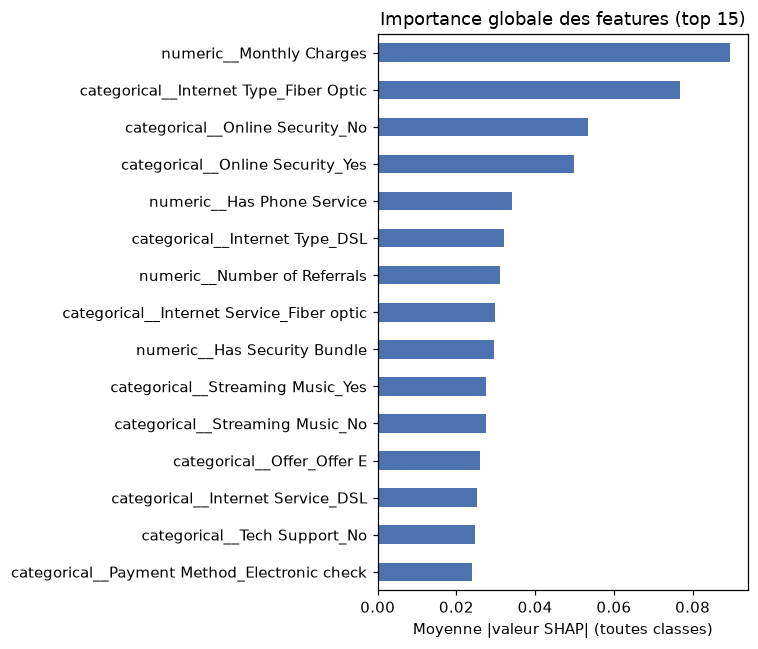

In [4]:
mean_abs_shap_global = np.abs(shap_values.values).mean(axis=(0, 2))
global_importance = pd.Series(mean_abs_shap_global, index=feature_names_t).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 6))
global_importance.head(15).iloc[::-1].plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_xlabel("Moyenne |valeur SHAP| (toutes classes)")
ax.set_title("Importance globale des features (top 15)")
plt.tight_layout()
fig.savefig(config.REPORTS_FIGURES_DIR / "shap_global_importance.png", dpi=120)
plt.show()


## 3. SHAP par classe

Les features les plus influentes diffèrent selon qu'on explique
Detractor, Passive ou Promoter — un mean|SHAP| global masque ces
différences.


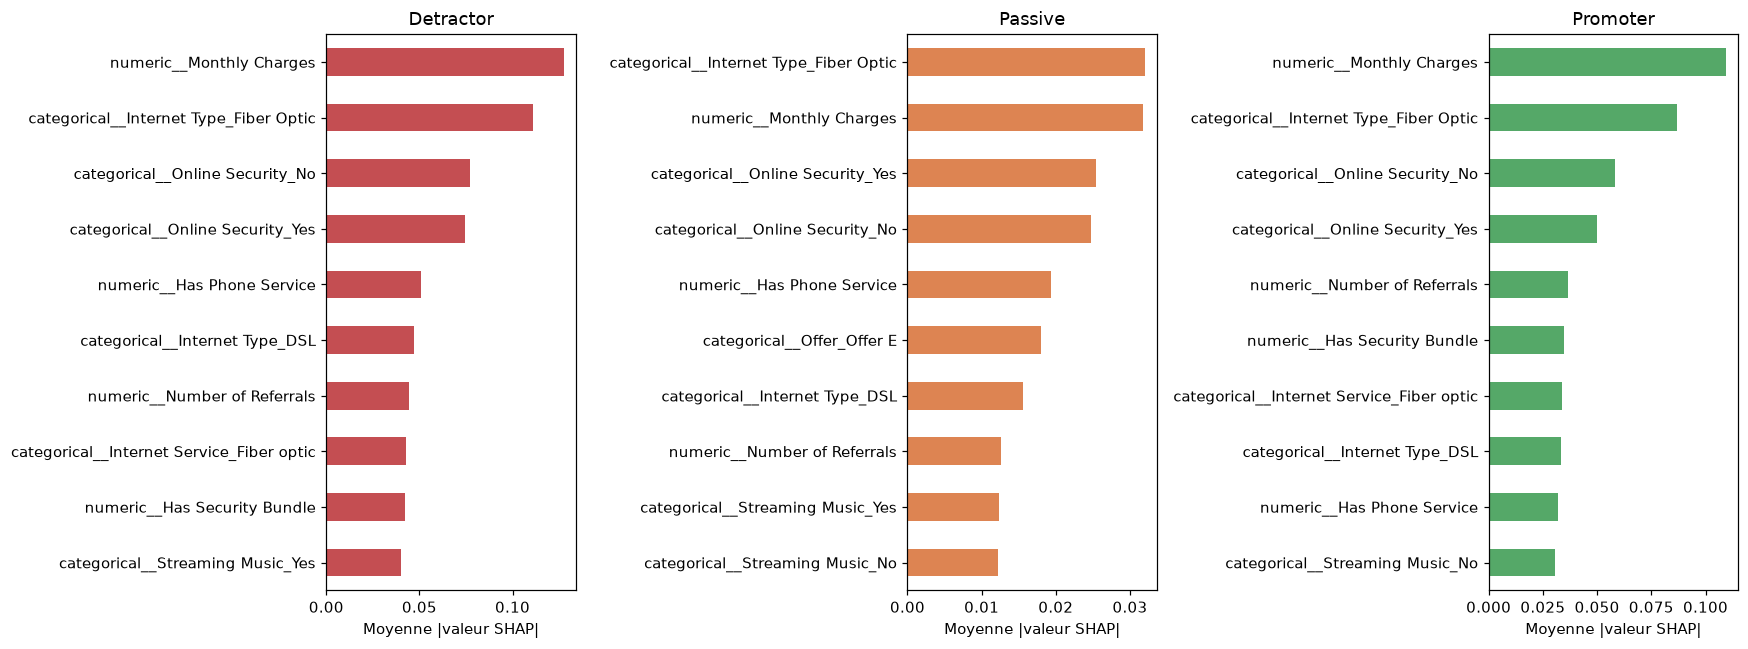

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
per_class_importance = {}
for ax, cls in zip(axes, config.NPS_CATEGORIES):
    idx = config.NPS_CATEGORIES.index(cls)
    imp = pd.Series(np.abs(shap_values.values[:, :, idx]).mean(axis=0), index=feature_names_t)
    imp = imp.sort_values(ascending=False)
    per_class_importance[cls] = imp
    imp.head(10).iloc[::-1].plot(kind="barh", ax=ax, color="#C44E52" if cls == "Detractor" else "#55A868" if cls == "Promoter" else "#DD8452")
    ax.set_title(cls)
    ax.set_xlabel("Moyenne |valeur SHAP|")
plt.tight_layout()
fig.savefig(config.REPORTS_FIGURES_DIR / "shap_by_class.png", dpi=120)
plt.show()


## 4. Dependence plots — 4 principaux drivers de détraction

Les 4 features avec le plus fort |SHAP| moyen pour la classe
**Detractor** spécifiquement (la priorité métier). Chaque point est un
client ; l'axe X est la valeur de la feature (après scaling pour les
numériques, 0/1 pour les colonnes catégorielles encodées), l'axe Y
l'impact SHAP sur la probabilité prédite de Detractor.


Top 4 drivers de Detractor: ['numeric__Monthly Charges', 'categorical__Internet Type_Fiber Optic', 'categorical__Online Security_No', 'categorical__Online Security_Yes']


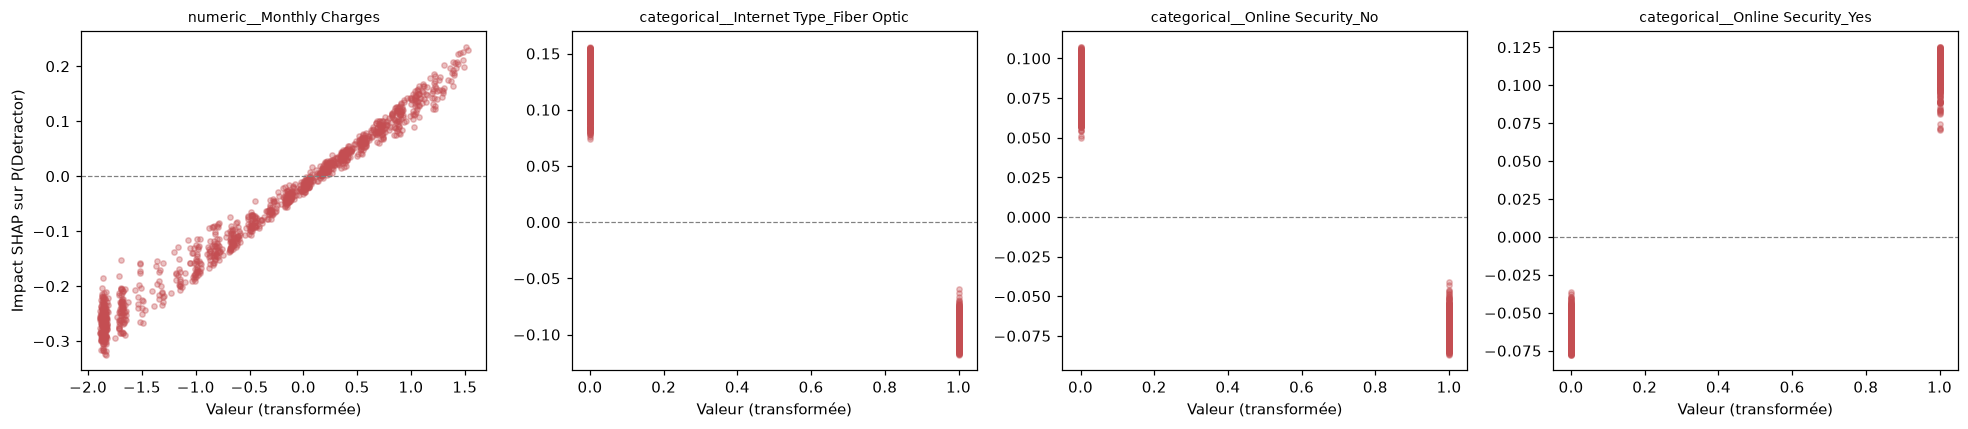

In [6]:
top4_detractor = per_class_importance["Detractor"].head(4).index.tolist()
print("Top 4 drivers de Detractor:", top4_detractor)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, feat in zip(axes, top4_detractor):
    feat_idx = list(feature_names_t).index(feat)
    x = X_sample_t[feat].to_numpy()
    y_shap = shap_values.values[:, feat_idx, DETRACTOR_IDX]
    ax.scatter(x, y_shap, alpha=0.35, s=12, color="#C44E52")
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(feat, fontsize=9)
    ax.set_xlabel("Valeur (transformée)")
axes[0].set_ylabel("Impact SHAP sur P(Detractor)")
plt.tight_layout()
fig.savefig(config.REPORTS_FIGURES_DIR / "shap_dependence_top4_detractor.png", dpi=120)
plt.show()


## 5. Analyse par segments

Les drivers de détraction sont-ils les mêmes selon le profil client ?
Comparaison du top 5 des features (par |SHAP| moyen sur la classe
Detractor) entre paires de segments : ancienneté (<12 vs >48 mois),
type de contrat (mensuel vs annuel), type d'accès internet (Fibre vs
DSL).


--- Ancienneté ---
  < 12 mois (n=398): ['numeric__Monthly Charges', 'categorical__Internet Type_Fiber Optic', 'categorical__Offer_Offer E', 'categorical__Online Security_No', 'categorical__Online Security_Yes']
  > 48 mois (n=313): ['numeric__Monthly Charges', 'categorical__Internet Type_Fiber Optic', 'categorical__Online Security_Yes', 'categorical__Online Security_No', 'numeric__Number of Referrals']
--- Type de contrat ---
  Month-to-month (n=699): ['numeric__Monthly Charges', 'categorical__Internet Type_Fiber Optic', 'categorical__Online Security_No', 'categorical__Online Security_Yes', 'categorical__Offer_Offer E']
  Contrat annuel (1-2 ans) (n=501): ['numeric__Monthly Charges', 'categorical__Internet Type_Fiber Optic', 'categorical__Online Security_Yes', 'categorical__Online Security_No', 'numeric__Has Phone Service']
--- Type d'accès internet ---
  Fibre (n=482): ['categorical__Internet Type_Fiber Optic', 'categorical__Online Security_No', 'categorical__Online Security_Yes', 'n

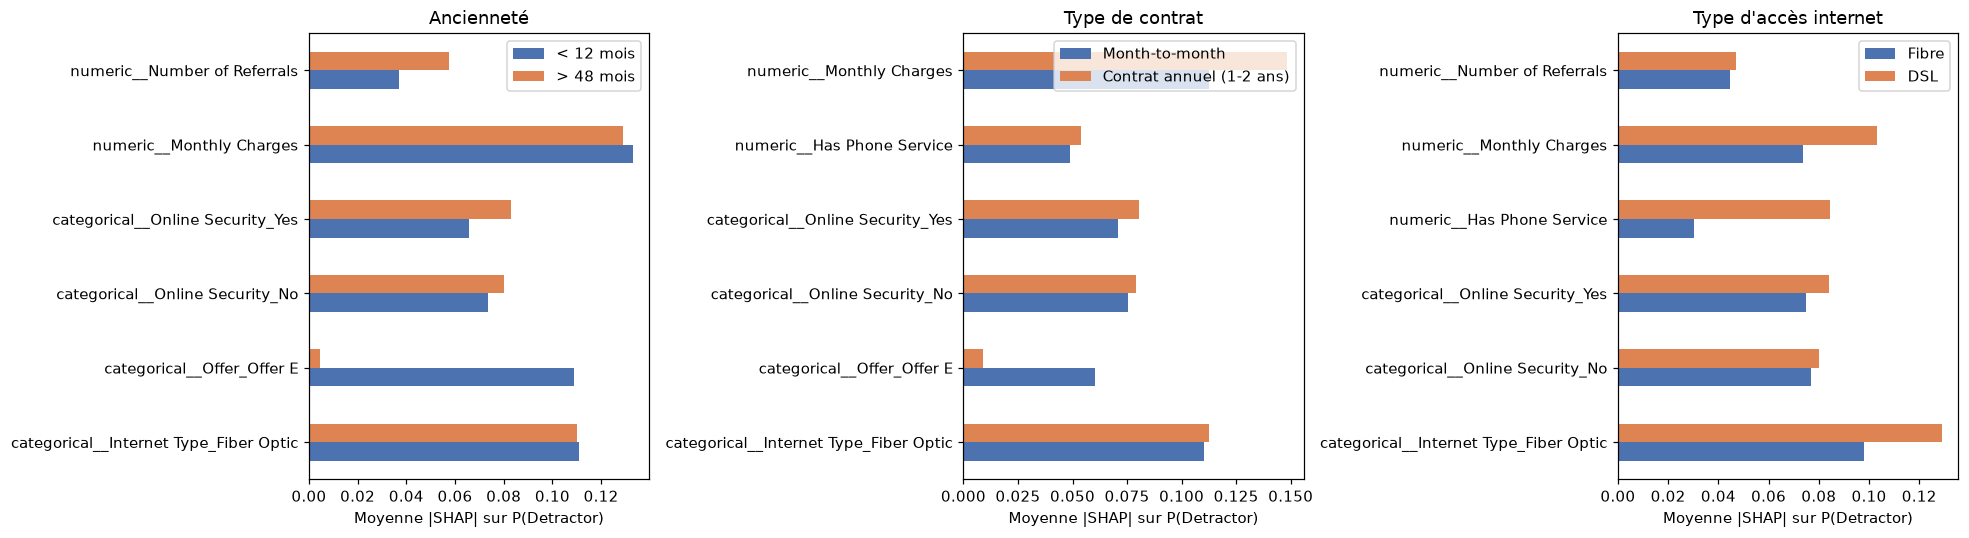

In [7]:
SEGMENT_DEFINITIONS = {
    "Ancienneté": {
        "< 12 mois": test_sample["Tenure Months"] < 12,
        "> 48 mois": test_sample["Tenure Months"] > 48,
    },
    "Type de contrat": {
        "Month-to-month": test_sample["Contract"] == "Month-to-month",
        "Contrat annuel (1-2 ans)": test_sample["Contract"].isin(["One year", "Two year"]),
    },
    "Type d'accès internet": {
        "Fibre": test_sample["Internet Service"] == "Fiber optic",
        "DSL": test_sample["Internet Service"] == "DSL",
    },
}

def top_features_for_mask(mask, k=5):
    idx_positions = np.flatnonzero(mask.to_numpy())
    imp = pd.Series(
        np.abs(shap_values.values[idx_positions, :, DETRACTOR_IDX]).mean(axis=0),
        index=feature_names_t,
    ).sort_values(ascending=False)
    return imp.head(k)


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (axis_name, groups) in zip(axes, SEGMENT_DEFINITIONS.items()):
    (label_a, mask_a), (label_b, mask_b) = groups.items()
    top_a = top_features_for_mask(mask_a)
    top_b = top_features_for_mask(mask_b)
    print(f"--- {axis_name} ---")
    print(f"  {label_a} (n={mask_a.sum()}): {list(top_a.index)}")
    print(f"  {label_b} (n={mask_b.sum()}): {list(top_b.index)}")

    combined_features = pd.Index(top_a.index).union(top_b.index)
    comparison = pd.DataFrame({
        label_a: pd.Series(
            np.abs(shap_values.values[np.flatnonzero(mask_a.to_numpy())][:, [list(feature_names_t).index(f) for f in combined_features], DETRACTOR_IDX]
                   ).mean(axis=0), index=combined_features),
        label_b: pd.Series(
            np.abs(shap_values.values[np.flatnonzero(mask_b.to_numpy())][:, [list(feature_names_t).index(f) for f in combined_features], DETRACTOR_IDX]
                   ).mean(axis=0), index=combined_features),
    })
    comparison.plot(kind="barh", ax=ax, color=["#4C72B0", "#DD8452"])
    ax.set_title(axis_name)
    ax.set_xlabel("Moyenne |SHAP| sur P(Detractor)")
plt.tight_layout()
fig.savefig(config.REPORTS_FIGURES_DIR / "shap_segments_comparison.png", dpi=120)
plt.show()


## 6. Drivers actionnables vs non-actionnables, et levier recommandé

**Constat principal : le même trio de drivers domine dans presque tous
les segments.** `Monthly Charges`, `Internet Type_Fiber Optic` et
`Online Security` (présence/absence) arrivent dans le top 4-5 pour
Detractor, quel que soit le segment (ancienneté, type de contrat, type
d'accès internet) — seul l'ordre relatif change. Ce n'est pas un
artefact du découpage par segment : c'est un signal robuste que ces
trois axes dominent la détraction dans ce dataset, indépendamment du
profil client.

| Driver | Actionnable ? | Levier |
|---|---|---|
| `Monthly Charges` | **Oui** | Révision tarifaire ciblée / remise de rétention pour les clients à charge élevée relativement à leur segment. |
| `Internet Type` (Fibre vs DSL/Cable) | **Partiellement** | Le type d'accès en soi dépend de l'infrastructure disponible chez le client, mais le grief sous-jacent (l'EDA phase 1 montrait des `Churn Reason` du type "Competitor offered more data/higher download speeds" pour les clients Fibre) est actionnable via la qualité de service ou le repositionnement prix de l'offre Fibre. |
| `Online Security` (absent) | **Oui** | Proposer/packager l'add-on Online Security de façon proactive plutôt qu'attendre une souscription spontanée. |
| Type de contrat (month-to-month) | **Oui** | Incitations à la montée vers un contrat annuel (déjà un driver secondaire dans plusieurs segments). |
| Ancienneté (tenure) | **Non directement** | On ne peut pas changer l'ancienneté d'un client, mais on peut adapter le traitement (ex. onboarding renforcé pour les nouveaux clients à risque). |
| Genre, Senior Citizen, Partner, Dependents | **Non — à ne jamais cibler** | Absents du top 5 dans tous les segments testés ici — signal préliminaire qui s'est révélé **partiellement trompeur** une fois vérifié directement : `src/fairness_audit.py` (D27) a trouvé un écart de rappel Detractor réel et statistiquement robuste sur `Dependents` (19 points), que l'importance SHAP globale ne laissait pas du tout deviner. Corrigé pour l'essentiel (D28, écart réduit à 12 points, coût de performance nul), mais un écart résiduel sur `Dependents` et un écart plus modeste sur `Gender` (5 points) persistent — voir section 7. |

**Levier recommandé, pour un Detractor prédit donné** : vérifier
d'abord `Monthly Charges` relativement à son segment de contrat/service
— si elevé, une remise ciblée est le levier le plus direct et le mieux
supporté par les données. Si le client est sur Fibre sans l'add-on
Online Security, une proposition combinée (bundle sécurité + geste
tarifaire) adresse les deux drivers dominants simultanément.

**Limite à ne pas oublier.** SHAP mesure une **association** apprise
par le modèle, pas une causalité : que `Monthly Charges` élevé soit
associé à la détraction ne prouve pas qu'une baisse de prix réduirait
mécaniquement la détraction (une causalité inverse est possible : les
clients déjà mécontents pourraient avoir souscrit à plus d'options,
ou vice-versa). Par ailleurs, D20 (phase 3) a montré que le classement
des features n'est que modérément stable sous bruit de label
(corrélation de rang de Spearman = 0.687 entre le modèle entraîné sur
le label baseline et sur le label bruité) — cette hiérarchie de drivers
doit être lue comme indicative, pas comme une vérité définitive.


